![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 6.02 Dense Neural Network (with PyTorch)

> Blockquote toevoegen


This will expand on our logistic regression example and take us through building our first neural network. If you haven't already, be sure to check (and if neccessary) switch to GPU processing by clicking Runtime > Change runtime type and selecting GPU. We can test this has worked with the following code:

In [1]:
import torch

# Check for GPU availability
print("Num GPUs Available: ", torch.cuda.device_count())

Num GPUs Available:  1


Hopefully your code shows you have 1 GPU available! Next let's get some data. We'll start with another in-built dataset:

In [2]:
# upload an in-built Python (OK semi-in-built) dataset
from sklearn.datasets import load_diabetes

import pandas as pd
import numpy as np

# import the data
data = load_diabetes()
data

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

We are working on a regression problem, with "structured" data which has already been cleaned and normalised. We can skip the usual cleaning/engineering steps. However, we do need to get the data into PyTorch:

In [3]:
# Convert data to PyTorch tensors
X = torch.tensor(data.data, dtype=torch.float32)
y = torch.tensor(data.target, dtype=torch.float32).reshape(-1, 1) # Reshape y to be a column vector

Now our data is stored in tensors we can do train/test splitting as before (in fact we can use sklearn as before):

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([353, 10]) torch.Size([353, 1])
torch.Size([89, 10]) torch.Size([89, 1])


Now we can set up our batches for training. As we have a nice round 400 let's go with batches of 50 (8 batches in total). We'll also seperate the features and labels:

In [6]:
from torch.utils.data import TensorDataset, DataLoader

# Create TensorDatasets and DataLoaders
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=50, shuffle=True)

test_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=50, shuffle=False)

Now its time to build our model. We'll keep it simple ... a model with an input layer of 10 features and then 2x _Dense_ (fully connected) layers each with 5 neurons and ReLU activation. Our output layer will be size=1 given this is a regression problem and we want a single value output per prediction.

This will be easier to understand if you have read through the logistic regression tutorial.

In [7]:
import torch
import torch.nn as nn

# Define the model
class DiabetesModel(nn.Module):
    def __init__(self):
        super(DiabetesModel, self).__init__()
        # we'll set up the layers as a sequence using nn.Sequential
        self.layers = nn.Sequential(

            # first layer will be a linear layer that has 5x neurons
            # (5x sets of linear regression)
            # the layer takes the 10 features as input (i.e. 10, 5)
            nn.Linear(10, 5),

            nn.ReLU(), # ReLU activation

            # second linear layer again has 5 neurons
            # this time taking the input as the output of the last layer
            # (which had 5x neurons)
            nn.Linear(5, 5),

            nn.ReLU(), # ReLU again

            # last linear layer takes the output from the previous 5 neurons
            # this time its a single output with no activation
            # i.e. this is the predicitons (regression)
            nn.Linear(5, 1)
        )

    def forward(self, x):
        return self.layers(x) # pass the data through the layers

As before we need to create a model object, specify the loss (criterion) and an optimiser (which we cover next week):

In [8]:
import torch.optim as optim

# Initialize the model, loss function, and optimizer
model = DiabetesModel()
criterion = nn.MSELoss() # MSE loss function
optimiser = optim.Adam(model.parameters(), lr=0.001)

Now we can train the model. Again, the logistic regression tutorial (6.01) may help you undertstand this:

In [9]:
# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training loop (example - you'll likely want to add more epochs)
epochs = 100 # 100 epochs

for epoch in range(epochs):
  # use the train_loader to pass the inputs (x) and targets (y)
  for inputs, targets in train_loader:
    # pass to the GPU (hopefully)
    inputs, targets = inputs.to(device), targets.to(device)

    # pass model to GPU as well
    model.to(device)

    model.train() # put the model object in train mode
    optimiser.zero_grad() # reset the gradiants
    outputs = model(inputs) # create outputs
    loss = criterion(outputs, targets) # compare with Y to get loss
    loss.backward() # backpropogate the loss (next week)
    optimiser.step() # # update the parameters based on this round of training

  # every 10 steps we will print out the current loss
    if (epoch+1) % 10 == 0: # modular arithmetic
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {round(loss.item(), 4)}')

Epoch [10/100], Loss: 30260.459
Epoch [10/100], Loss: 26183.9551
Epoch [10/100], Loss: 28915.1992
Epoch [10/100], Loss: 30688.4473
Epoch [10/100], Loss: 29311.2793
Epoch [10/100], Loss: 28158.3027
Epoch [10/100], Loss: 35273.2852
Epoch [10/100], Loss: 20343.8203
Epoch [20/100], Loss: 29978.2852
Epoch [20/100], Loss: 26099.459
Epoch [20/100], Loss: 28793.6348
Epoch [20/100], Loss: 29386.8711
Epoch [20/100], Loss: 33847.7539
Epoch [20/100], Loss: 26904.5645
Epoch [20/100], Loss: 33309.5
Epoch [20/100], Loss: 20584.5859
Epoch [30/100], Loss: 33899.4062
Epoch [30/100], Loss: 25726.2852
Epoch [30/100], Loss: 26382.6289
Epoch [30/100], Loss: 32752.1562
Epoch [30/100], Loss: 26928.9492
Epoch [30/100], Loss: 32348.8496
Epoch [30/100], Loss: 30341.5996
Epoch [30/100], Loss: 6256.7046
Epoch [40/100], Loss: 31825.3438
Epoch [40/100], Loss: 28559.8984
Epoch [40/100], Loss: 34040.7148
Epoch [40/100], Loss: 28089.2852
Epoch [40/100], Loss: 29314.5039
Epoch [40/100], Loss: 25724.3418
Epoch [40/100], 

We can see loss is significantly lower at the end than it was at the start. However, it is also bouncing around a little still which suggests the model needs more training (100 epochs is not a lot in deep learning terms). However, let's evaluate as before:

In [10]:
# Evaluation (example)
model.eval() # testing mode
mse_values = [] # collect the MSE scores

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs) # predict the test data

        # Calculate Mean Squared Error
        mse = criterion(outputs, targets) # calcualte mse for the batch
        mse_values.append(mse.item()) # add to the list of MSE values

# Calculate and print the average MSE
avg_mse = np.mean(mse_values)
print(f"Average MSE on test set: {avg_mse}")

Average MSE on test set: 19563.0205078125


MSE looks expected given training (no obvious sign of overfitting). However, we probably can get better results with tuning and more epochs.

Let's run the loop again a little differently to collect the predicted values (y_hat) and actuals (y) and add them to a dataset for comparions:

In [11]:
# Evaluation
model.eval()
predictions = []
actuals = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        predictions.extend(outputs.cpu().numpy())
        actuals.extend(targets.cpu().numpy())

# Create DataFrame
results_df = pd.DataFrame({'Predicted': np.array(predictions).flatten(), 'Actual': np.array(actuals).flatten()})
results_df

,Predicted,Actual
0,25.670454,219.0
1,24.687399,70.0
2,25.437054,202.0
3,32.018898,230.0
4,24.713190,111.0
...,...,...
84,22.200615,153.0
85,20.484802,98.0
86,18.643108,37.0
87,19.208641,63.0


Side-by-side, they don't look great. Can you improve them?

<br><br>

## EXERCISE #1
Try increasing the number of epochs to 1,000 (when the model is fairly well trained then the results printed for each 10x epochs will be fairly stable and not change much). Does this give better results?

<br><br>

## EXERCISE #2 (optional)
Try experimenting with the architecture (number of neurons and/or number of layers). Can we reach an optimal architecture?

EXERCISE 1

In [12]:
import torch.nn as nn, torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_model(hidden_sizes, in_dim=10):
    layers = []
    for h in hidden_sizes:
        layers += [nn.Linear(in_dim, h), nn.ReLU()]
        in_dim = h
    layers.append(nn.Linear(in_dim, 1))          # no activation: regression
    return nn.Sequential(*layers)

def train_eval(hidden_sizes, epochs=1000, lr=0.001, print_every=100):
    torch.manual_seed(42)                         # fair comparison between runs
    model = build_model(hidden_sizes).to(device)
    criterion = nn.MSELoss()
    optimiser = optim.Adam(model.parameters(), lr=lr)
    history = []

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimiser.zero_grad()
            loss = criterion(model(inputs), targets)
            loss.backward()
            optimiser.step()
            running += loss.item() * len(inputs)
        history.append(running / len(train_loader.dataset))   # mean loss per epoch
        if print_every and (epoch + 1) % print_every == 0:
            print(f"Epoch [{epoch+1}/{epochs}] train MSE: {history[-1]:.1f}")

    model.eval()
    with torch.no_grad():
        preds = model(X_test.to(device)).cpu().numpy().flatten()
    actual = y_test.numpy().flatten()
    return model, history, preds, actual, mean_squared_error(actual, preds), r2_score(actual, preds)

# Exercise 1: original architecture (5,5), 100 vs 1000 epochs
_, h100,  p100,  actual, mse100,  r2_100  = train_eval([5, 5], epochs=100,  print_every=0)
_, h1000, p1000, _,      mse1000, r2_1000 = train_eval([5, 5], epochs=1000)
print(f"100 epochs : test MSE {mse100:.0f}, R² {r2_100:.2f}")
print(f"1000 epochs: test MSE {mse1000:.0f}, R² {r2_1000:.2f}")

Epoch [100/1000] train MSE: 26770.3
Epoch [200/1000] train MSE: 15494.3
Epoch [300/1000] train MSE: 5905.2
Epoch [400/1000] train MSE: 4129.7
Epoch [500/1000] train MSE: 3877.8
Epoch [600/1000] train MSE: 3690.2
Epoch [700/1000] train MSE: 3532.2
Epoch [800/1000] train MSE: 3408.8
Epoch [900/1000] train MSE: 3303.1
Epoch [1000/1000] train MSE: 3215.0
100 epochs : test MSE 23772, R² -3.49
1000 epochs: test MSE 2994, R² 0.43


,Predicted,Actual
0,163.268661,219.0
1,166.349365,70.0
2,156.468216,202.0
3,279.684875,230.0
4,145.359253,111.0
5,122.791504,84.0
6,225.171326,242.0
7,199.266891,272.0
8,107.446686,94.0
9,127.618576,96.0


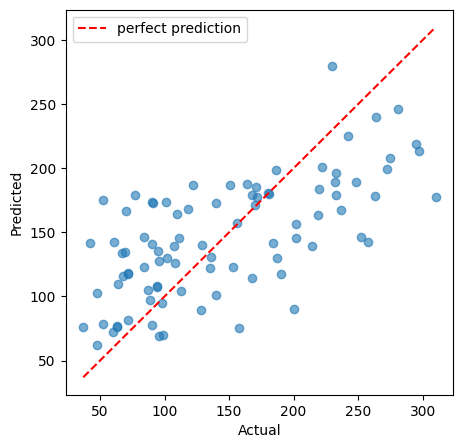

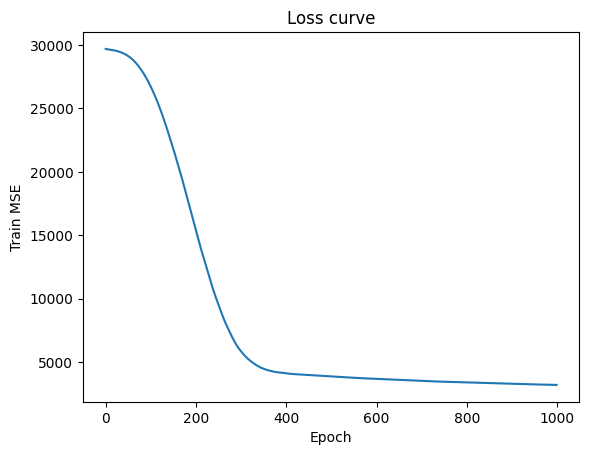

In [13]:
results_df = pd.DataFrame({"Predicted": p1000, "Actual": actual})
display(results_df.head(10))

plt.figure(figsize=(5,5))
plt.scatter(actual, p1000, alpha=0.6)
lims = [actual.min(), actual.max()]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.legend(); plt.show()

plt.plot(h1000); plt.xlabel("Epoch"); plt.ylabel("Train MSE"); plt.title("Loss curve"); plt.show()

Yes. Increasing training from 100 to 1,000 epochs reduced test MSE from ~23,800 to ~3,000 and raised R² from −3.5 ,which is worse than predicting the mean, to 0.43. The loss curve falls steeply until about epoch 400, then flattens (3,878 to 3,215 between epochs 500 and 1,000), so the model is largely converged. Train and test MSE are similar, so there is no sign of overfitting. The model was previously underfit, not badly specified.

Exercise 2


In [14]:
configs = {"[5,5] (baseline)": [5,5], "[16]": [16], "[16,16]": [16,16],
           "[64,32]": [64,32], "[64,32,16]": [64,32,16], "[128,64,32]": [128,64,32]}

rows = []
for name, hs in configs.items():
    _, hist, preds, actual, mse, r2 = train_eval(hs, epochs=1000, print_every=0)
    rows.append({"architecture": name, "train MSE (final)": hist[-1], "test MSE": mse, "test R²": r2})

summary = pd.DataFrame(rows).sort_values("test MSE")
display(summary)

,architecture,train MSE (final),test MSE,test R²
5,"[128,64,32]",2784.284162,2714.651611,0.487623
4,"[64,32,16]",2827.180166,2787.820557,0.473813
3,"[64,32]",2878.854157,2858.629883,0.460448
2,"[16,16]",2908.334462,2885.761963,0.455327
0,"[5,5] (baseline)",3214.974643,2994.176270,0.434864
1,[16],3277.550530,3029.284424,0.428238


I trained six architectures for 1,000 epochs each, with a fixed seed, and compared them on the test set. Test MSE improved with capacity: the baseline [5,5] scored 2,994 (R² 0.43), and the largest network, [128,64,32], scored 2,715 (R² 0.49). Train and test MSE were close in every case, so none of the models overfit, and the gains came from reducing underfitting. The improvement flattens quickly (about 9% from the smallest to the largest network), which suggests the data, not the architecture, is the limiting factor. With about 350 training rows and 10 features, R² near 0.5 is close to what a simple linear model achieves on this dataset.

So no single optimal architecture can be claimed. [128,64,32] performed best of those tested, but the trend had not yet turned upward, so a larger network might do slightly better. Differences of 50–100 MSE between neighbouring architectures are likely within seed and split noise. Also, choosing the best model on the test set leaks information, so its test score is slightly optimistic. A proper approach would use a validation set or cross-validation, and multiple random seeds, to select the architecture.